# Análisis pra cadena Model Fitness 

### La cadena de gimnasios Model Fitness está desarrollando una estrategia de interacción con clientes basada en datos analíticos.
### ¿Cómo descubres si un/a cliente ya no está contigo? 
### Con el fin de combatir la cancelación, Model Fitness ha digitalizado varios de sus perfiles de clientes. La tarea consiste en analizarlos y elaborar una estrategia de retención de clientes.

### Model Fitness me aportó archivos CSV que contienen los datos sobre la cancelación de un mes en concreto e información del mes que lo precedía. El dataset incluye los siguientes campos:

-'Churn' — la cancelación para el mes en cuestión
- Campos de dataset actuales:
- Datos del usuario del mes anterior
- 'gender'.
- 'Near_Location' — si el/la usuario/a vive o trabaja en el vecindario donde se encuentra el gimnasio.
- 'Partner' — si el/la usuario/a trabaja en una compañía asociada (el gimnasio tiene empresas asociadas cuyos empleados obtienen -    descuentos; en esos casos el gimnasio almacena información sobre los empleadores de los clientes).
- Promo_friends — si el/la usuario/a originalmente se inscribió mediante una oferta “trae a un/a amigo/a” (se utilizó el código promocional de un/a amigo/a cuando pagaron el primer abono).
- 'Phone' — si el/la usuario/a aportó el número de teléfono.
- 'Age'.
- 'Lifetime' — el tiempo (en meses) desde que el/la usuario/a llegó por primera vez al gimnasio.
- Datos del registro de visitas y compras y datos sobre el estado actual de la membresía:
- 'Contract_period' — 1 mes, 3 meses, 6 meses o 1 año.
- 'Month_to_end_contract' — los meses que faltan hasta que expire el contrato.
- 'Group_visits' — si el/la usuario/a participa en sesiones grupales.
- 'Avg_class_frequency_total' — frecuencia media de visitas por semana a lo largo de la vida del cliente.
- 'Avg_class_frequency_current_month' — frecuencia media de visitas por semana durante el mes en curso.
- 'Avg_additional_charges_total' — cantidad total de dinero gastado en otros servicios del gimnasio: cafetería, productos deportivos, cosméticos, masajes, etc.

In [ ]:
# Comenzar con lo escencial, la importación de librerias para el proyecto 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt 
import numpy as np 
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram,linkage
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler 
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import Lasso,Ridge 
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor 
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score 
from sklearn.metrics import mean_absolute_percentage_error 
from sklearn.metrics import accuracy_score, precision_score,recall_score,f1_score

### Paso 1 Carga de los datos

In [ ]:
#Carga de datos y Lectura del data frame 
df_gym = pd.read_csv('/datasets/gym_churn_us.csv')

### Paso 2 LLvar acabo el enalisi exploratorio de los datos 

In [ ]:
#Primer acercamiento a los datos 
print(df_gym.shape)
print(df_gym.describe())
df_gym.info()

(4000, 14)
            gender  Near_Location      Partner  Promo_friends        Phone  \
count  4000.000000    4000.000000  4000.000000    4000.000000  4000.000000   
mean      0.510250       0.845250     0.486750       0.308500     0.903500   
std       0.499957       0.361711     0.499887       0.461932     0.295313   
min       0.000000       0.000000     0.000000       0.000000     0.000000   
25%       0.000000       1.000000     0.000000       0.000000     1.000000   
50%       1.000000       1.000000     0.000000       0.000000     1.000000   
75%       1.000000       1.000000     1.000000       1.000000     1.000000   
max       1.000000       1.000000     1.000000       1.000000     1.000000   

       Contract_period  Group_visits          Age  \
count      4000.000000   4000.000000  4000.000000   
mean          4.681250      0.412250    29.184250   
std           4.549706      0.492301     3.258367   
min           1.000000      0.000000    18.000000   
25%           1.00000

In [ ]:
#Obcervación de los valores medios de las caracteristicas en grupos 
df_gym.groupby('Churn').mean()

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month
Churn,,,,,,,,,,,,,
0,0.510037,0.873086,0.534195,0.353522,0.903709,5.747193,0.464103,29.976523,158.445715,5.283089,4.711807,2.024876,2.027882
1,0.510839,0.768143,0.355325,0.183789,0.902922,1.728558,0.268615,26.989632,115.082899,1.662582,0.990575,1.474995,1.044546


### Despues de el primer acercamiento alos datos, tenemos los formatos correctos, la limpieza adecuada y el promedio de cancelacion.

# Histograma de barras y distribuciones de caracteristicas para las personas que se fueron y las que se quedaron 

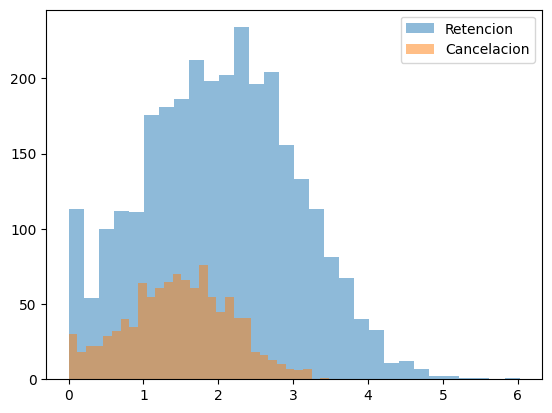

In [ ]:
plt.hist(df_gym[df_gym['Churn'] == 0]['Avg_class_frequency_total'], bins = 30, alpha = 0.5, label = 'Retencion')
plt.hist(df_gym[df_gym['Churn'] == 1]['Avg_class_frequency_total'], bins = 30, alpha = 0.5, label = 'Cancelacion')
plt.legend()
plt.show()

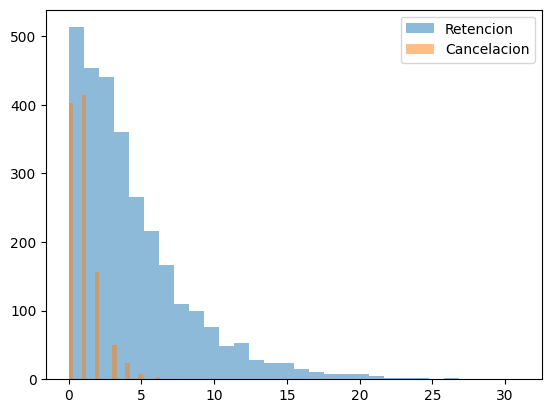

In [ ]:
plt.hist(df_gym[df_gym['Churn'] == 0]['Lifetime'], bins = 30, alpha = 0.5, label = 'Retencion')
plt.hist(df_gym[df_gym['Churn'] == 1]['Lifetime'], bins = 30, alpha = 0.5, label = 'Cancelacion')
plt.legend()
plt.show()

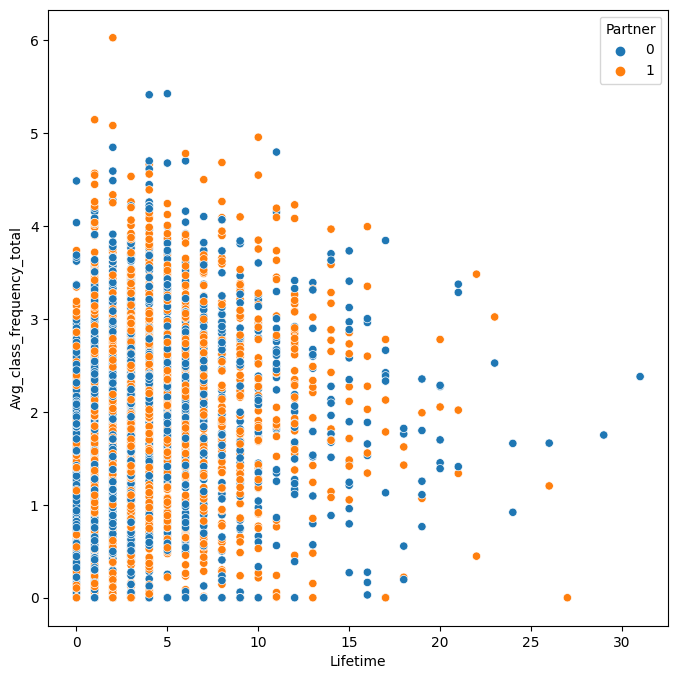

In [ ]:
# Grafico de dispersion para compara columnas relacionadas 
plt.figure(figsize=(8,8))
sns.scatterplot(x= 'Lifetime', y = 'Avg_class_frequency_total', data = df_gym, hue = 'Partner')
plt.show()

# Matriz de correlacion acompañado de su grafico de calor 

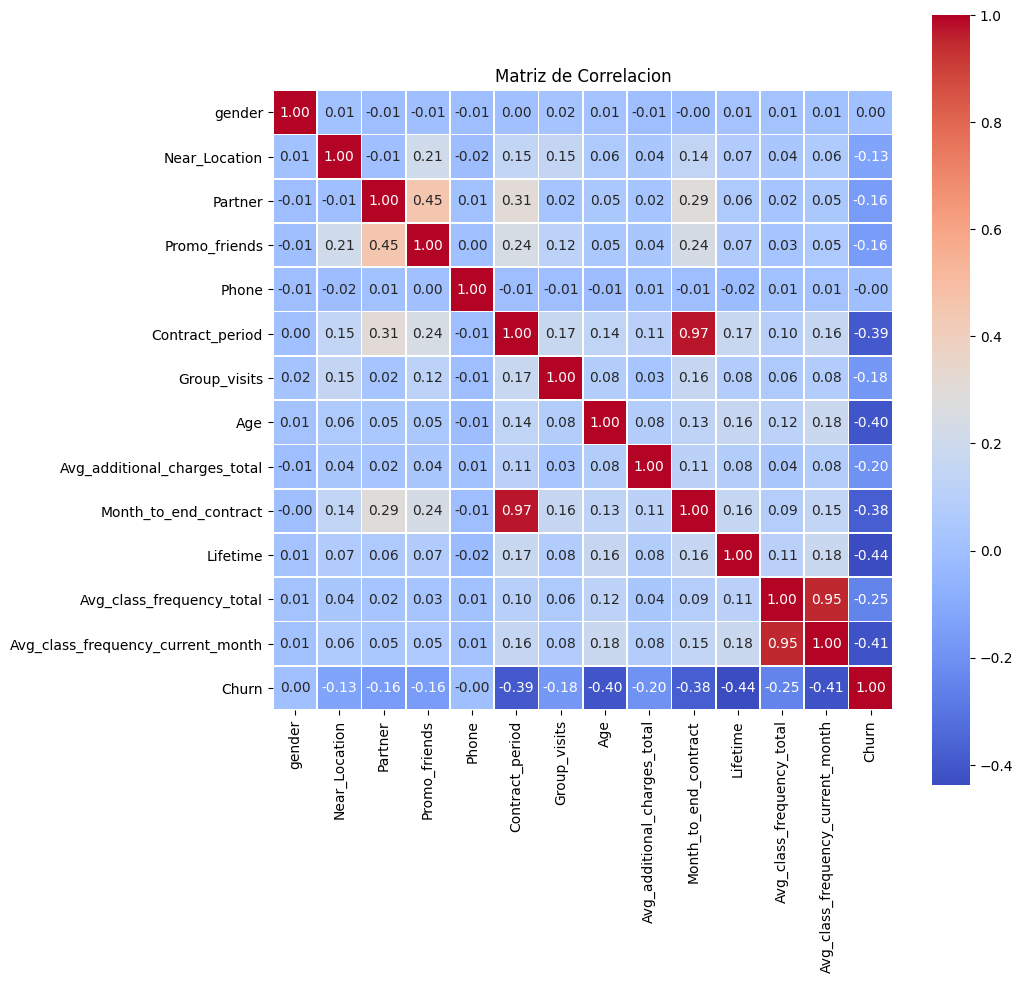

In [ ]:
# Crear un a matriz de correlacion 
corr_m = df_gym.corr()

# Grafico de la matriz 
plt.figure(figsize=(10,10))
sns.heatmap(corr_m, square = True, annot = True, cmap = 'coolwarm', fmt = '.2f', linewidths = 0.5)
plt.title('Matriz de Correlacion')
plt.show()

#### Tenemos una correlacion con numeros negativos a la cabeza, osea entre menos tiempo, menos clases y ,mas jovenes, mas se van, lo cual puede tener algo de sentido, los miebros nuevos, solo entran por moda o para cumplir un proposito que queda resagado en el camino despues de un tiempo, algo curioso, los que vienen en pareja traen mas amigos con promocion, seria un buen punto de oportunidad para incentivar a quedarse a mas gente.
### Solo se debe tener en cuenta que no siempre correlación significa causalidad, puede que en algunos casos tengamos variables altamente correlacionadas pero no necesariamente son causa una de la otra

### Paso 3 Construir un modelo para predecir la cancelación de usuarios

In [ ]:
scaler = StandardScaler()
scaler.fit(df_gym[['Age', 'Lifetime', 'Contract_period', 'Avg_class_frequency_current_month', 'Avg_class_frequency_total', 'Avg_additional_charges_total', 'Month_to_end_contract']])
X_sc = scaler.transform(df_gym[['Age', 'Lifetime', 'Contract_period', 'Avg_class_frequency_current_month', 'Avg_class_frequency_total', 'Avg_additional_charges_total', 'Month_to_end_contract']])
new_df_gym = pd.DataFrame(data = X_sc, columns = ['Age', 'Lifetime', 'Contract_period', 'Avg_class_frequency_current_month', 'Avg_class_frequency_total', 'Avg_additional_charges_total', 'Month_to_end_contract'])

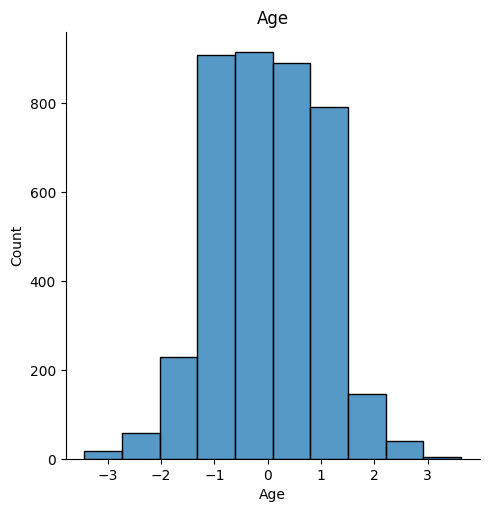

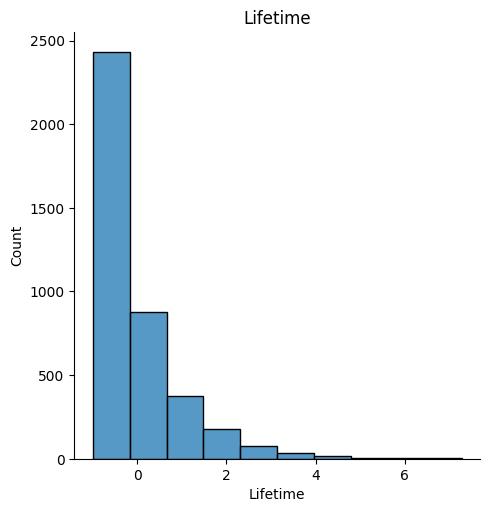

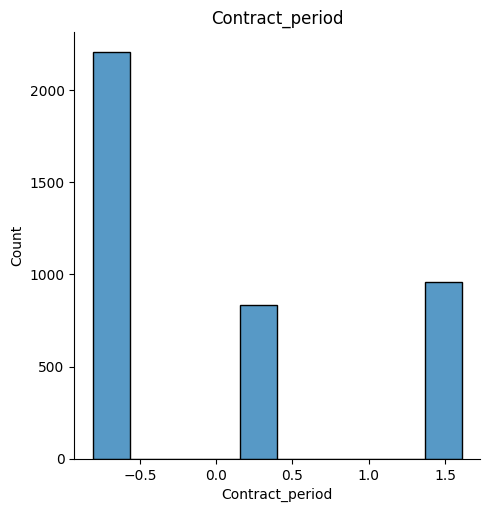

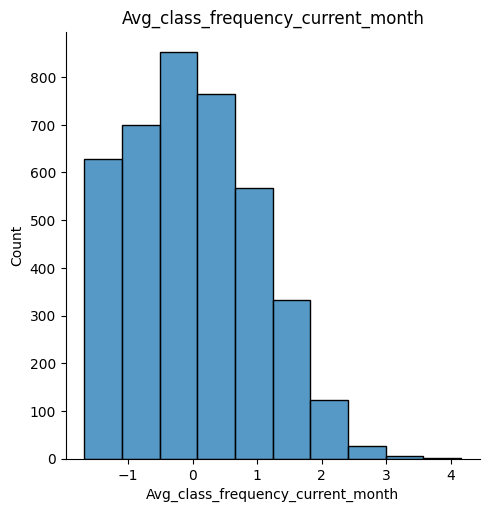

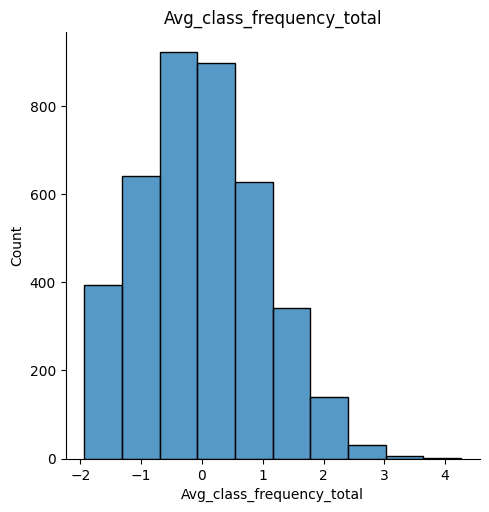

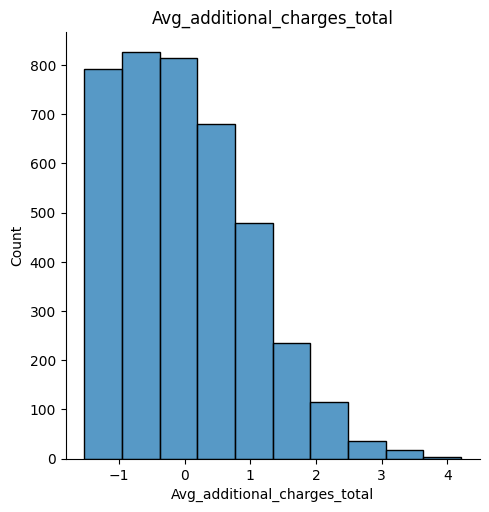

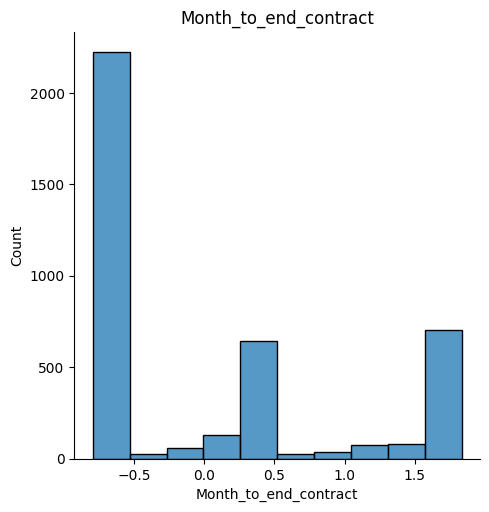

In [ ]:
for feature in new_df_gym.columns:
    sns.displot(new_df_gym[feature], bins = 10)
    plt.title(feature)
    plt.show()   

In [ ]:
# Divicion de los datos en conjuntos de entrenamiento y validacion 
X = new_df_gym
y = df_gym['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

# Estandarizar datos 
scaler = StandardScaler()
scaler.fit(X_train)
X_train_st = scaler.transform(X_train)
X_test_st = scaler.transform(X_test) 

# Entrenamiento de modelo de regrecion 
log_reg_model = LogisticRegression()
log_reg_model.fit(X_train_st, y_train)
y_pred = log_reg_model.predict(X_test_st)

# Calculo de metricas 
print('CALCULO DE METRICAS LOGISTICREGRESSION')
print('Accuracy:{:.2f}'.format(accuracy_score(y_test, y_pred)))
print('Precision:{:.2f}'.format(precision_score(y_test, y_pred)))
print('Recall:{:.2f}'.format(recall_score(y_test, y_pred)))
print('F1:{:.2f}'.format(f1_score(y_test, y_pred)))

CALCULO DE METRICAS LOGISTICREGRESSION
Accuracy:0.93
Precision:0.87
Recall:0.83
F1:0.85


In [ ]:
# Divicion de los datos en conjuntos de entrenamiento y validacion 
X = new_df_gym
y = df_gym['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

# Estandarizar datos 
scaler = StandardScaler()
scaler.fit(X_train)
X_train_st = scaler.transform(X_train)
X_test_st = scaler.transform(X_test)

# Entrenar modelo con bosque aleatorio
rf_model = RandomForestClassifier()
rf_model.fit(X_train_st, y_train)
y_pred = rf_model.predict(X_test_st)

# Calculo de metricas 
print('CALCULO DE METRICAS RANDOMFORESTCLASSIFIER')
print('Accuracy:{:.2f}'.format(accuracy_score(y_test, y_pred)))
print('Precision:{:.2f}'.format(precision_score(y_test, y_pred)))
print('Recall:{:.2f}'.format(recall_score(y_test, y_pred)))
print('F1:{:.2f}'.format(f1_score(y_test, y_pred)))

CALCULO DE METRICAS RANDOMFORESTCLASSIFIER
Accuracy:0.92
Precision:0.86
Recall:0.82
F1:0.84


#### Tomando en cuenta las metricas metricas Precision y Recall,  el modelo LoggisticRegresion supera por una diferencia peqeuña pero notable, en Precision tenemos 87 contra 85 y en Recall tenemos 83 contra 82, lo cual nos dice que el modelo acerto de manera mas exacta en las preguntas clave, ¿que porcentage que se fue? , y ¿que porcentage logro detectar que se fue?

#### Es importante darle prioridad a Precision para no caer en informacion de mala calidad, si podemos contar con informacion confiable podemos encontrar estagias de calidad y dirigidas al objetivo, esto en el caso concreto del gymnacio para lograr la retencion de clientes que a suvez permitira un negocio sano y numeros positivos la mayor arte del tiempo de operación.

#### Si bien Recall es una metrica importante, antes de ir directo al fatalismo, podemos prevenir antes de sufrir la perdida, es importante cuidar los costos, pero, si nos enfocamos a lo que podemos 'controlar' en lugar de todo aquello que esta fuera de las manos, podemos encontrar mejores estragias e incluso promociones o incentivos para lograr una retencion efectiva 

### Paso 4 Crear clusters de usuarios 

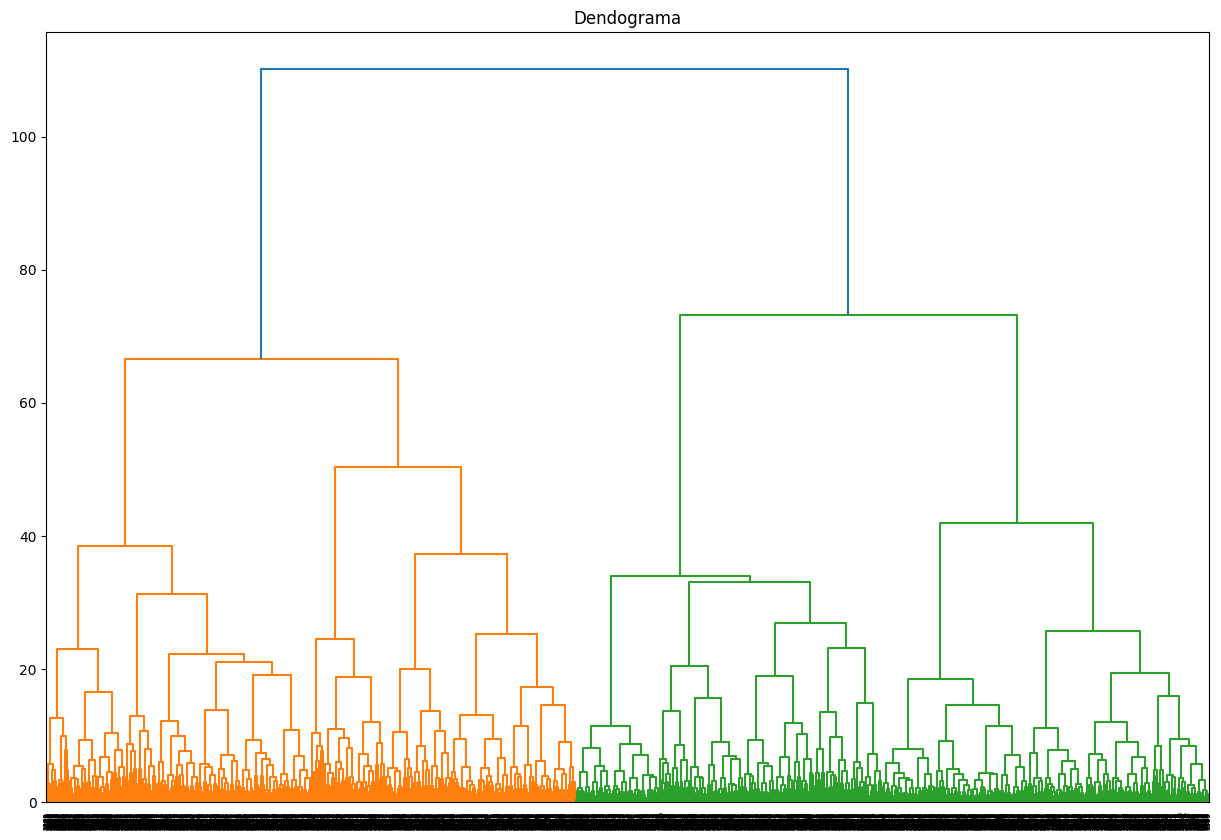

In [ ]:
# Estandarizar los datos 
sc= StandardScaler()
X_cs = sc.fit_transform(X)
#Utiliza la función linkage() para crear una matriz de distancias basada en la matriz de características estandarizada y trazar un dendrograma.
linked = linkage(X_cs, method = 'ward')

plt.figure(figsize= (15,10))
dendrogram(linked, orientation = 'top')
plt.title('Dendograma')
plt.show()

# Estandarizacion obligatoria antes de pazarla al algoritmo 

In [ ]:
sc = StandardScaler()
X_sc = sc.fit_transform(X)

km = KMeans(n_clusters = 5)
labels = km.fit_predict(X_sc)

print(labels)

[1 2 1 ... 2 4 4]


# Agregar la columna 'labels'al DF original df_gym 

In [ ]:
df_gym['labels'] = labels 
df_gym.head(5)

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn,labels
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0,1
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0,2
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0,1
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0,2
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0,1


In [ ]:
# Tamaño de cada cluster 
df_gym['labels'].value_counts()

1    1447
3    1054
4     641
2     558
0     300
Name: labels, dtype: int64

# Valores medios de caracteristic para los cluster 

In [ ]:
df_gym.groupby('labels').mean()

- 0    0.003333
- 1    0.624741
- 2    0.012545
- 3    0.103416
- 4    0.062402
- Name: Churn, dtype: float64

In [ ]:
# Calculo de cancelacion para cada cluster
df_gym['Churn'].groupby(labels).mean()

0    0.003333
1    0.624741
2    0.012545
3    0.103416
4    0.062402
Name: Churn, dtype: float64

#### Toamndo en cuenta los datos obtenidos, el cluster numero 1 es el que tiene el promedio mas alto de 'Churn', seguido del cluster 0, y en tercer lugar esta el cluster 2.
#### Si tomamos en cuenta el contract_period del cluster mas alto '1' es de 1.63 con un life_time de 1.8, y el contract_period del cluster mas bajo '4', podemos obcervar que curiosamente este es de 3.65 con u life_time de 12.7, los clientes estan fiemando contratos por periodos cortos, pero aun asi, la permanencia es prolongada en el caso dela cluster mas bajo, en ambos casos el cluster mas alto tiene un promedio de visitas de 1.2 mientras que el cluster mas bajo tiene 1.8, el cluster mas alto gasta un promedio extra al mes de 120.19 mientras que l cluster mas bajo llega a un promedio de 147.


#### los grupos propensos a cancelar son el cluster 1, 0 y 2. y aunque parezca raro el mas leal es el cluster 4 

### Paso 5 

#### Los clientes buscan firmar contratos cortos, una buena sugerencia sería implementar y sugeriri domiciliar el pago, buscando ofrecer algun tipo de incentivo al hacerlo, meces gratis, descuento en otras amenidades serian una buena estrategia.
#### Los clienters que firman contratos cortos pero que su promedio como cliente es corto, se les puede encaminar a un programa de recompensas, o en su caso, ofrecer algun tipo de 2x1 o quiza 1.5 x 1, se puede explorar incluir clases extra gratis las primeras 6 semanas para que se queden un promedio mas alto.
#### Abordar al cluster numero 1 con algun incentivo para que gaste un poco mas en los extras, quiza un kit de bienvenida, ofrecer refil de cafe o proteina usando un termo de regalo podria funcionar para incentivar el gasto y al menos obtener un margen mas alto sin importar que se quede o se retire. 


### QUEDO ATENDO A SUS OBCERVACIONES Y COMENTARIOS, LAS USGERENCIAS SE PUEDEN MODIFICAR OADECUAR DEACUERDO AL PLAN DEL DEPARTAMENTO ENCARGADO.

### ATTE. CÉSAR RODRIGRUEZ JR.DATA ANAKLIS 